# Imports

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import wntr
import wntr.graphics as wntr_graphics
import networkx as nx
import os
import torch
import random
from torch_geometric.data import Data
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
from sklearn.metrics import classification_report, confusion_matrix

from data_use import (
    normalizar_residuo, taxa_exceedance, calcular_residuo
)

from data_access import (
    get_all, leak_info
)

from data_menagement import (
    process_scenario_data
)

# Prep G

In [2]:
def map_graph(scenarios):
    # carregar topologia
    wn = wntr.network.WaterNetworkModel(scenarios[118]['inp'])
    G = wn.to_graph().to_undirected()

    # lista em ordem fixa de nós
    list_nodes = sorted(wn.junction_name_list, key=int)
    nodes_index = {node: i for i, node in enumerate(list_nodes)} # enumerate devolve par (posição, valor) pra cada elemento de uma lista

    print(list_nodes)
    print(nodes_index)

    return G, list_nodes, nodes_index

In [3]:
def build_edge(G, nodes_index):
    # construir edge_index bidirecional
    start_edge = []
    end_edge = []

    for u, v in G.edges(): 
        # pula qualquer aresta que envolva um nó fora do mapeamento (reservatório)
        if u not in nodes_index or v not in nodes_index:
            continue
        
        idx_u = nodes_index[u]
        idx_v = nodes_index[v]

        start_edge.extend([idx_u, idx_v]) # .extend adiciona múltiplos elementos ao final de uma lista de uma só vez
        end_edge.extend([idx_v, idx_u])

    # cria tensor no formato certo
    edge_index = torch.tensor([start_edge, end_edge], dtype=torch.long)

    return edge_index


In [17]:
def build_scenario_data_graph(scenarios, list_nodes, nodes_index, edge_index, janela_dias, window_size, step):
    list_data = []

    for n, item in scenarios.items():
        dfs_nodes, leak_intervals, total_steps = process_scenario_data(item, list_nodes, janela_dias)

        # cada pedaço dão 24 horas de histórico
        for t_init in range(0, total_steps - window_size + 1, step):
            t_end = t_init + window_size

            # dentro de cada janela de 24 horas, cria-se um grafo novo (Data) para a GNN
            # cria a matriz de features x (len com todos nodes da rede) e correspondência y
            n_nodes = len(list_nodes)
            x = torch.zeros((n_nodes, 48), dtype=torch.float)
            y = torch.zeros(n_nodes, dtype=torch.long)

            # for each node, pega a tb tratada (dfs_nodes), cuts 24h from current window e calc mean error_normalizado
            # mean.error_normalizado = feature x[node] naquele grafo
            for node in list_nodes:
                idx = nodes_index[node]
                df_node = dfs_nodes[node]

                # extract slice from error_normalizado nessa window
                slice = df_node['error_normalizado'].iloc[t_init:t_end].values

                # if not len() = 48
                if len(slice) < 48:
                    continue

                # defines the values
                for i, val in enumerate(slice):
                    x[idx, i] = float(val)

                # gabarito
                is_leaking = False
                for leak_node, (start, end) in  leak_intervals.items():
                    # leakege is happening in this window and in this node?
                    if str(node) == str(leak_node) and not (t_end < start or t_init > end):
                        is_leaking = True
                        break

                y[idx] = 1 if is_leaking else 0

            data = Data(x=x, edge_index=edge_index, y=y)
            list_data.append(data)

    return list_data

## Refactor: Transição de "Momento de Pico" para "Sliding Windows"

### 1. Por quê?

Anteriormente, a primeira feature do modelo era focada em **momentos de pico**, sendo a avalição de instantes isolados em que o resíduo ultrapassava um limiar crítico. A modelagem utilizando Redes Neurais em Grafos (GNNs) esbarrou em limitações físicas e matemáticas.

- **Suscetibilidade a Ruído (Falsos Positivos):** Avaliar um único *timestep* torna o modelo vulnerável a anomalias instantâneas e benignas da rede (como o acionamento de uma bomba, um fechamento abrupto de válvula ou oscilações de sensor), que geram picos isolados, mas não são vazamentos reais.
- **Perda do Contexto Temporal:** Um vazamento físico de água não é um evento de um milissegundo; ele possui persistência e altera o padrão de despressurização ao longo do tempo. 

**Instrução do orientador:** Técnica de **Sliding Windows**.
Ao invés de usar picos isolados, o modelo passa a analisar o comportamento sustentado da rede em blocos contínuos de tempo (ex: janelas de 24 horas). Isso permite que a GNN aprenda a "assinatura temporal" de um vazamento prolongado.


### 2. Implementação Técnica e Refatoração

Para viabilizar a técnica de Sliding Windows, a arquitetura de extração de dados passou por um grande refactor, principalmente na função `build_scenario_data`:

* Os 17.500 *timesteps* contínuos de um cenário não são mais convertido em um único grafo gigante. A função agora recorta esse histórico e gera múltiplos grafos sequenciais, onde cada grafo representa a rede em uma janela específica (de `t_inicio` a `t_fim`).

* Em vez de alimentar a rede com o erro de um único ponto no tempo, a feature de entrada passou a ser uma agregação estatística. O `error_normalizado` de todos os instantes dentro da janela de 24 horas é extraído para calcular a média daquele período (pensar melhor). 

* O tensor `data.x` resultante **não representa o histórico de um único nó**. Ele é uma matriz que contém o valor médio daquela janela temporal para **todos os nós** da rede simultaneamente.
  > Ou seja, significa que, com base na média de todos os `error_normalizado` de um dia inteiro para um nó, ele poderá ter seu desvio padrão resumido em 24h.

* **Preservação da Escala Global (`x_stack`):** 
  Como a rede neural avalia as "fotografias" (`data.x`) isoladamente, a normalização espacial não poderia ser feita janela a janela (o que destruiria o contexto de grandeza entre elas). O `StandardScaler` foi treinado sobre a variável `x_stack`, que empilha todas as janelas, de todos os nós, de todos os cenários. Isso garante que a média `0.0` seja ancorada no comportamento histórico global do dataset, permitindo que a GNN diferencie uma janela normal de uma janela anômala através da variância.


### 3. Por que não janela semanal?

O consumo de água em uma cidade segue o padrão dia-noite (24h).
Uma janela de 1 semana iria diluir o sinal do vazamento, isso suavizaria a queda de pressão provocada pelo vazamento e sumiria no ruído estatístico da semana inteira.

Com cenários que tem 17.500 timesteps, usar janelas de 48 steps com `step=48` vai gerar uma quantidade de grafos de treino sem deixar o modelo fixado em detalhes logos e nem perdido detalhes curtos.

Processa um cenário por vez, fazendo slicing a cada 24h e retorna uma lista de grafos referentes àquele cenário. Cada grafo tem armazenado um valor específico em cada nó.

### 4. Baseline segura

Cenários com múltiplos vazamentos precisam do início do primeiro vazamento como referência, pois é antes de qualquer alteração crítica, mantendo a média saudável.

O `earliest_start` na função `build_scenario_data` passa por todos os vazamentos do cenário, identifica o menor `start` absoluto e usa isso para calcular o baseline de normalização em um momento em que a rede está livre.


# Action

In [18]:
scenarios = get_all("train")
    # path
    # inp
    # info
    # leaks
    # pressures

G, list_nodes, nodes_index = map_graph(scenarios)
edge_index = build_edge(G, nodes_index)

data_list_train = build_scenario_data_graph(scenarios, list_nodes, nodes_index, edge_index, janela_dias=14, window_size=48, step=48)


['2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32']
{'2': 0, '3': 1, '4': 2, '5': 3, '6': 4, '7': 5, '8': 6, '9': 7, '10': 8, '11': 9, '12': 10, '13': 11, '14': 12, '15': 13, '16': 14, '17': 15, '18': 16, '19': 17, '20': 18, '21': 19, '22': 20, '23': 21, '24': 22, '25': 23, '26': 24, '27': 25, '28': 26, '29': 27, '30': 28, '31': 29, '32': 30}


## Normalizações
### Normalização física por nó (Z-Score de baseline)

O objetivo era padronizar o resíduo de pressão de cada nó em relação ao seu próprio histórico (pré-vazamento).

Para cada nó, foi calculado o resíduo móvel de pressão. 
$$\text{error\_movel} = \text{Value} - \text{esperado\_movel}$$
  2. Isola-se a série temporal referente ao período pré-vazamento ($t < \text{start}$) para extrair a média ($\mu_{\text{baseline}}$) e o desvio-padrão ($\sigma_{\text{baseline}}$) históricos daquele nó.
  3. Aplica-se a padronização Z-score sobre a série inteira:
     $$z = \frac{\text{error\_movel} - \mu_{\text{baseline}}}{\sigma_{\text{baseline}}}$$

**Por quê?** 

Cada ponto da rede possui características físicas distintas (elevação, proximidade com reservatórios, diâmetro dos tubos). Isso garante que a referência normal de todos os nós seja centralizada em $0$ durante a operação saudável, medindo as oscilações de pressão em unidades de desvio-padrão em relação ao próprio comportamento do nó.

### Att: deleção de célula de normalização por StandardScaler
#### [DELETED] Padronização global do dataset (StandardScaler)

A normalização por Z-Score foi feita individualmente no histórico de cada nó usando o baseline pr=e-vazamento na função `normalizar_residuo`. Ou seja, os dados de cada tudo já saem centralizados em 0 e ajustados à própria realidade física.

O vetor de 48 features preserva a física, pois a GNN enxerga a curva temporal real do desvio de pressão daquele nó. Aplicar `StandardScaler` global em cima de 48 colunas escalonaria cada coluna de horário de forma isolada, o que deformaria o formato da onda que a rede precisa captar.


Total de valores Normais (0): 4842528
Total de valores com Vazamento (1): 45552


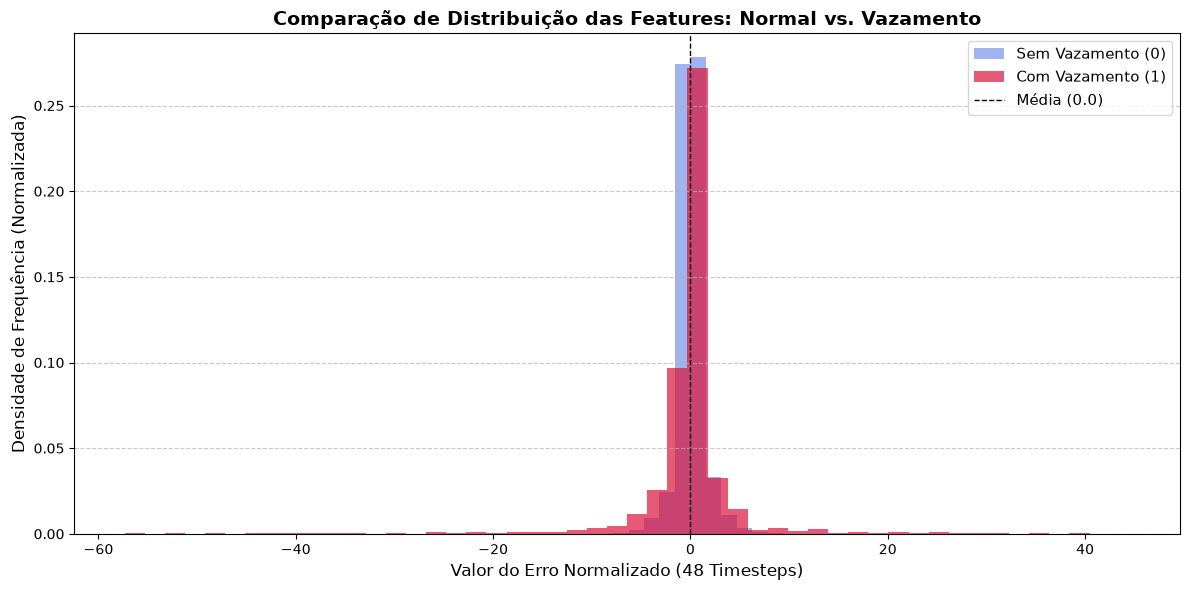

In [ ]:
# data prepare for plot

valores_classe_0 = []
valores_classe_1 = []

for data in data_list_train:
    x_np = data.x.numpy()  # formato: (31 nós, 48 timesteps)
    y_np = data.y.numpy()  # formato: (31 nós,)
    
    # Para cada nó do grafo desta janela:
    for node_idx in range(len(y_np)):
        features_do_no = x_np[node_idx] # Os 48 timesteps desse nó
        rotulo = y_np[node_idx]         # Se esse nó específico está vazando (1) ou não (0)
        
        if rotulo == 0:
            valores_classe_0.extend(features_do_no)
        else:
            valores_classe_1.extend(features_do_no)

valores_classe_0 = np.array(valores_classe_0)
valores_classe_1 = np.array(valores_classe_1)

print(f"Total de valores Normais (0): {len(valores_classe_0)}")
print(f"Total de valores com Vazamento (1): {len(valores_classe_1)}")

# plotagem

plt.figure(figsize=(12, 6))

plt.hist(valores_classe_0, bins=50, alpha=0.5, color='royalblue', density=True, label='Sem Vazamento (0)')
if len(valores_classe_1) > 0:
    plt.hist(valores_classe_1, bins=50, alpha=0.7, color='crimson', density=True, label='Com Vazamento (1)')
else:
    print("Aviso: Nenhum dado de vazamento foi encontrado para plotar.")

plt.axvline(0, color='black', linestyle='--', linewidth=1, label='Média (0.0)')

plt.title('Comparação de Distribuição das Features: Normal vs. Vazamento', fontsize=14, fontweight='bold')
plt.xlabel('Valor do Erro Normalizado (48 Timesteps)', fontsize=12)
plt.ylabel('Densidade de Frequência (Normalizada)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

A plotagem compara o comportamento da rede de água em duas situações diferentes.

**Eixo x**: apresenta o tamanho do desvio da pressão em relação ao que seria o "normal" histórico daquele tubo. A escala ir de -60 a +40 documenta a variação extrema de pressão que a rede passou.

**Eixo y**: apresenta a densidade de frequência (normalizada). A diferença de quantidade entre as duas classes é muito grande, então esse eixo mostra a proporção relativa dentro de cada classe, ou seja, mostra a % de dados de determinada classe que se concentra naquela faixa específica de erro.

## Validação com plotagem
**Objetivo**: Validar a aplicação da dupla normalização (temporal-local via média móvel e espacial-global via `StandardScaler`) sobre o dataset completo de treinamento.

---

### 1. Construção dos dados
**Cálculo do `error_movel`(resíduo bruto)**

Definição do comportamento esperado para cada nó. Agrupa-se cada instante do dia em grupos de 14 dias e calcula-se a média da pressão de cada horário. O `error_movel` é a diferença entre a pressão do momento em análise e a média do mesmo horário nos últimos 14 dias para o mesmo nó. 

Os primeiros dias (antes de 14 dias terem se passado) são registrados com `error_movel` = 0.

**Normalização local / Z-Score** 

O `error_movel`, então, é convertido para unidades de desvio-padrão (Z-Score) e o **Baseline** é definido como a média e o desvio-padrão do período saudável do cenário (antes do primeiro vazamento).

Assim, o `error_normalizado` mede a situação do nó em relação ao seu período saudável.

**Window Slicing method** 

Recorte do histórico operacional em janelas contínuas de 24 horas (48 timesteps). Em vez de resumir o comportamento do nó com uma média, o modelo preserva a assinatura temporal completa do período.

Cada nó da rede tem um vetor de entrada `x` composto por 48 valores sequenciais do `error_normalizado` dentro de uma janela específica.

O objetivo é fazer com que a GNN aprende a magnitude do desvio e a dinâmica temporal de propagação da anomalia ao longo do dia.

**Escala final**

A normalização local por `Z-Score` baseada no período saudável foi aplicada diretamente sobre a série temporal de cada nó em relação ao seu próprio histórico, por isso os dados entram na GNN com variância controlada e centralizados em todo do comportamento esperado de operação. 

---

### 2. Interpretação do estado dos dados

O histograma comparativo representa a distribuição consolidada de todos os valores de `error_normalizado` (ao longo de 48 timesteps) extraídos de todas as janelas de tempo, segmentados de acordo com o gabarito das classes (classe $0$ para nós saudáveis e classe $1$ para nós com vazamento ativo).

**Distribuição geral do Histograma**

Ambas as distribuições apresentam um pico concentrado ao redor de $0.0$, o que retrata a maioria das observações da rede serem em estado normal de operação. Mesmo em cenários com vazamentos, muitos nós ou momentos iniciais de anomalia operam com pressões muito próximas do comportamento histórico esperado. 

**Análise das Caudas e Assinatura de Vazamento**

A principal distinção visual ocorre nos extremos das distribuições. A classe $0$ decai próxima ao centro, enquanto a classe $1$ estende-se em direção a valores extremos (range de -60 a +40 desvios-padrão)

Esses outliers representam as quedas e distorções abruptas de pressão provocadas pelo vazamento.

### 3. Conclusão

As features temporais são validas para ingestão na Graph Neural Network (GNN).

Justificativas: 
1. **Preservação do sinal físico:** Desvios extremos nas pontas garantem que há sinal suficiente para distinguir anomalias.
2. **Desafio de fronteira:** A sopreposição das classes no núcleo central reforça a necessidade de um modelo baseado em Grafos (GNN), capaz de ir além de limiares simples para explorar a topologia. 

### Sanity check

In [20]:
print(f"Total de exemplos de treino: {len(data_list_train)}")

count = 0 
for i, data in enumerate(data_list_train):
    n_marcados = (data.y == 1).sum().item()
    if n_marcados > 0:
        count += 1

print(f"Janelas com vazamento: {count}")

Total de exemplos de treino: 3285
Janelas com vazamento: 877


In [21]:
# Verifica se sobrou algum NaN ou Infinito na lista de treino
tem_nan = False
for i, data in enumerate(data_list_train):
    if torch.isnan(data.x).any() or torch.isinf(data.x).any():
        print(f"Cuidado: O grafo {i} possui valores NaN ou Inf em x!")
        tem_nan = True

if not tem_nan:
    print("Nenhum NaN encontrado nas features x. O dataset está limpo estruturalmente.")

Nenhum NaN encontrado nas features x. O dataset está limpo estruturalmente.


# Train

In [22]:
# Divisão sistemática dos dados
random.seed(42)
idx = list(range(len(data_list_train)))
random.shuffle(idx)

cut = int(0.8 * len(idx))
idx_train = idx[:cut]
idx_val = idx[cut:]

train_data = []
for i in idx_train:
    train_data.append(data_list_train[i])

val_data = []
for j in idx_val:
        val_data.append(data_list_train[j])

print(f"Treino: {len(train_data)}, Validação: {len(val_data)}")

Treino: 2628, Validação: 657


In [23]:
class GCNSimples(torch.nn.Module):
    def __init__(self, n_features, hidden_channels, n_classes):
        super().__init__()
        self.conv1 = GCNConv(n_features, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, hidden_channels)
        self.conv3 = GCNConv(hidden_channels, n_classes)
    
    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = self.conv2(x, edge_index)
        x = F.relu(x)
        x = self.conv3(x, edge_index)

        return x

In [29]:
from torch_geometric.loader import DataLoader

# cria DataLoader
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False)

# condig model
modelo = GCNSimples(48, 64, 2)
otimizador = torch.optim.Adam(modelo.parameters(), lr=0.0005)
w_class = torch.tensor([1.0, 150.0])
modelo.train()

for epoca in range(100):
    total_loss = 0

    for batch in train_loader:
        otimizador.zero_grad()                   # zera os gradientes acumulados da rodada anterior

        # PyG groups graphs automatically no objeto 'batch'
        output = modelo(batch.x, batch.edge_index) # faz a previsão (forward pass)

        loss = F.cross_entropy(output, batch.y, weight=w_class)   # calcula o erro
        loss.backward()                          # calcula os gradientes (o quanto cada peso contribuiu pro erro)
        otimizador.step()                        # ajusta os pesos na direção que reduz o erro
        
        total_loss += loss.item()

    if epoca % 10 == 0:
        print(f"Época {epoca}, perda total: {total_loss:.4f}")
        

Época 0, perda total: 71.8800
Época 10, perda total: 49.2025
Época 20, perda total: 45.9121
Época 30, perda total: 43.4579
Época 40, perda total: 40.8672
Época 50, perda total: 39.1538
Época 60, perda total: 39.0770
Época 70, perda total: 36.3854
Época 80, perda total: 35.7385
Época 90, perda total: 34.4391


## Refatoração do Pipeline de Treinamento: Adoção de Mini-Batching (DataLoader)

### 1. Contexto da Mudança
Na versão passada do pipeline, a iteração de treinamento era feita diretamente sobre a lista de grafos (`for data in train_data`). Isso significava que o modelo realizava o processo de *Forward Pass*, *Loss* e *Backpropagation* **grafo a grafo** (processando apenas uma janela temporal de 24 horas por vez).

Seguindo orientação, a abordagem manual foi substituída pela classe `DataLoader` nativa do PyTorch Geometric (PyG), introduzindo o conceito de **Mini-Batching** (agrupamento de grafos) no treinamento.

### 2. O que mudou

#### Antes (Batch Size = 1)
O modelo atualizava seus pesos internos (gradientes) após olhar para apenas 1 print da rede.
* **Problema:** Como cada print pode ser muito diferente da outro (um sem vazamento, o próximo com um vazamento enorme), a direção de correção dos pesos estava desorientada. A Loss tendia à instabilidade, além de subutilizar o processamento vetorial da CPU/GPU.

> **Adendo: Moticação inicial dessa arquitetura**
>
> Quando o foco da detecção era baseado em **"momentos de pico"**, cada grafo representava um evento singular e isolado no tempo. Nessa lógica, avaliar a anomalia e ajustar os pesos imediatamente após cada instante fazia sentido arquitetural. No entanto, com a evolução da modelagem para a técnica de **Sliding Windows** — onde um vazamento deixa de ser um pico isolado e passa a ser compreendido como um padrão comportamental contínuo —, o treinamento individualizado tornou-se instável. A transição para o `DataLoader` (Mini-Batching) surgiu, portanto, como uma exigência natural para estabilizar a leitura dessas novas janelas temporais contínuas.

#### Depois (Batch Size = 32)
Com o `DataLoader(batch_size=32)`, o modelo agora recebe 32 grafos de uma só vez, calcula o erro de todas as 32 janelas, **tira a média desses erros**, e só então ajusta os pesos (Backpropagation).

* **Resultado:** Os gradientes ficam muito mais estáveis. O modelo aprende a direção correta de forma mais suave e consistente (Mini-Batch Gradient Descent).

----------------------- 

### 3. A Engenharia do PyTorch Geometric: O "Super Grafo"
Diferente de imagens ou textos, grafos não têm um tamanho fixo (nem sempre têm o mesmo número de nós ou arestas). Por isso, não dá para simplesmente empilhar grafos em uma nova dimensão de matriz tradicional.

Para resolver isso de forma elegante, quando o `DataLoader` do PyG cria um `batch`, ele junta os 32 grafos em **um único "Super Grafo" gigante e desconectado**:
* O novo `batch.x` empilha os nós de todos os 32 grafos vertiginosamente.
* O novo `batch.edge_index` ajusta os índices das conexões para que um grafo não se conecte por engano com o outro grafo do mesmo batch (cria uma Matriz de Adjacência em Bloco Diagonal).
* Assim, passamos para a nossa GCNSimples um único super grafo por rodada. A rede neural processa tudo de forma vetorizada simultaneamente sem saber que, na verdade, está analisando 32 dias diferentes.

### 4. Vantagens Técnicas Incorporadas
1. **Shuffle (Embaralhamento):** Ao ativar `shuffle=True` no `train_loader`, quebramos a correlação temporal. O modelo é forçado a prever vazamentos baseando-se nas features físicas do grafo, e não simplesmente "decorando" a ordem cronológica dos dias. (O `val_loader` mantém `shuffle=False` para preservar a análise metódica de validação).
2. **Performance (Vetorização):** O treinamento é executado em matrizes maiores (32x), aproveitando ao máximo as operações de álgebra linear otimizadas do PyTorch. O tempo por época (epoch) cai drasticamente.
3. **Ajuste de Pesos de Classe:** Aproveitando a refatoração, o peso da classe de anomalia (`w_class`) foi ampliado de 15.0 para 50.0 na Cross Entropy. Como a rede agora enxerga 32 exemplos por vez, a esmagadora maioria será da classe "0" (sem vazamento). O peso 50.0 força a rede a penalizar severamente os falsos negativos, mantendo o foco do aprendizado na detecção dos vazamentos.

# Evaluation

In [30]:
modelo.eval()  # modo avaliação (desliga alguns comportamentos específicos de treino, boa prática)
n_graphs = len(val_data)

exact_right = 0
leak_graphs = 0
leak_right = 0

all_pred = []
all_gab = []

for data in val_data: 
    with torch.no_grad():  # não precisa calcular gradiente aqui, só queremos ver a previsão
        out =  modelo(data.x, data.edge_index)
        pred = out.argmax(dim=1)

    # Coleta para o relatório nó a nó
    all_pred.extend(pred.cpu().numpy())
    all_gab.extend(data.y.cpu().numpy())

    if torch.equal(pred, data.y):
        exact_right += 1

    if (data.y == 1).sum() > 0:
        leak_graphs += 1

        if (pred == data.y).all(): 
            leak_right += 1

print("=== AVALIAÇÃO DE GRAFO PERFEITO ===\n")
print(f"Total de grafos: {n_graphs}")
print(f"Graphs with leaks: {leak_graphs}")
print(f"Acertou todos os nós: {exact_right}")
print(f"Acertou momento de leak: {leak_right}")

print("\n=== RAIO-X NÓ A NÓ (Desempenho Real) ===\n")
print(confusion_matrix(all_gab, all_pred))
print(classification_report(all_gab, all_pred, target_names=['Normal (0)', 'Vazamento (1)']))

=== AVALIAÇÃO DE GRAFO PERFEITO ===

Total de grafos: 657
Graphs with leaks: 161
Acertou todos os nós: 394
Acertou momento de leak: 0

=== RAIO-X NÓ A NÓ (Desempenho Real) ===

[[15038  5158]
 [   36   135]]
               precision    recall  f1-score   support

   Normal (0)       1.00      0.74      0.85     20196
Vazamento (1)       0.03      0.79      0.05       171

     accuracy                           0.74     20367
    macro avg       0.51      0.77      0.45     20367
 weighted avg       0.99      0.74      0.85     20367



O método de avaliação é global e também de nó a nó. 

A avaliação do grafo perfeito exige que todos os nós sejam preditos corretamente em uma mesma janela de 24 horas, o que faz com que tenha `Acertou momento de leak: 0`. 

Já a avaliação nó a nó utiliza a matriz de confusão e métricas granulares como `Precision`, `Recall` e `F1-Score`, pois, em vez de buscar um grafo perfeito, avalia o comportamento de cada tubo isoladamente.

A capacidade de avaliar isoladamente demonstrou que o modelo já consegue discernir entre momentos de vazamento e não vazamento, apesar de disparar **MUITOS** falsos negativos, por conta da sensibilidade.